Day 5: Module 2 CNN Improvement Project

In this notebook, I will compare a simple baseline CNN with an improved CNN that uses data augmentation, dropout, weight decay, a learning-rate scheduler, and early stopping. I will use the same train/validation split for both models and keep the test set for the final evaluation.

This is the module project. The aim is to compare the learning curves and final results, not to guarantee a particular accuracy.

Imports and setup

In [3]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 128
MAX_EPOCHS = 12
PATIENCE = 3
NUM_WORKERS = 2

Device: cuda


Load CIFAR-10 and make a fixed split

In [4]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

# Baseline training uses only tensor conversion and normalization.
baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Improved training adds random crops and horizontal flips.
improved_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

baseline_full = datasets.CIFAR10(root="data", train=True, download=True, transform=baseline_transform)
improved_full = datasets.CIFAR10(root="data", train=True, download=True, transform=improved_train_transform)
eval_full = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(baseline_full), generator=generator).tolist()
train_indices, val_indices = indices[:45000], indices[45000:]

baseline_train = Subset(baseline_full, train_indices)
improved_train = Subset(improved_full, train_indices)
val_data = Subset(eval_full, val_indices)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available()
}
baseline_train_loader = DataLoader(baseline_train, shuffle=True, **loader_kwargs)
improved_train_loader = DataLoader(improved_train, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_data, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_data, shuffle=False, **loader_kwargs)

print(f"Train: {len(train_indices)} | Validation: {len(val_indices)} | Test: {len(test_data)}")

100%|██████████| 170M/170M [59:31<00:00, 47.7kB/s]


Train: 45000 | Validation: 5000 | Test: 10000


Define the CNN

In [5]:
class CIFAR10CNN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        classifier_layers = [
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU()
        ]
        if use_dropout:
            classifier_layers.append(nn.Dropout(p=0.4))
        classifier_layers.append(nn.Linear(128, 10))
        self.classifier = nn.Sequential(*classifier_layers)

    def forward(self, x):
        return self.classifier(self.features(x))

criterion = nn.CrossEntropyLoss()

Training and evaluation functions

In [6]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

def train_model(model, train_loader, use_regularization=False, use_scheduler=False):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4 if use_regularization else 0.0
    )
    scheduler = None
    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=1
        )

    history = {
        "epoch": [], "train_loss": [], "train_accuracy": [],
        "val_loss": [], "val_accuracy": [], "lr": []
    }
    best_val_loss = float("inf")
    best_state = None
    no_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)

        if scheduler is not None:
            scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)
        history["lr"].append(current_lr)

        print(f"Epoch {epoch:02d} | train acc {train_acc:.2%} | val acc {val_acc:.2%} | val loss {val_loss:.4f} | lr {current_lr:g}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1

        if use_scheduler and no_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history, model

Train the baseline CNN

In [7]:
baseline_model = CIFAR10CNN(use_dropout=False).to(device)
baseline_history, baseline_model = train_model(
    baseline_model,
    baseline_train_loader,
    use_regularization=False,
    use_scheduler=False
)

Epoch 01 | train acc 47.12% | val acc 55.08% | val loss 1.2448 | lr 0.001
Epoch 02 | train acc 63.41% | val acc 67.10% | val loss 0.9305 | lr 0.001
Epoch 03 | train acc 70.06% | val acc 70.96% | val loss 0.8249 | lr 0.001
Epoch 04 | train acc 74.79% | val acc 72.76% | val loss 0.7675 | lr 0.001
Epoch 05 | train acc 77.87% | val acc 73.34% | val loss 0.7611 | lr 0.001
Epoch 06 | train acc 80.96% | val acc 73.70% | val loss 0.7810 | lr 0.001
Epoch 07 | train acc 83.64% | val acc 75.32% | val loss 0.7492 | lr 0.001
Epoch 08 | train acc 85.91% | val acc 75.06% | val loss 0.7882 | lr 0.001
Epoch 09 | train acc 87.94% | val acc 74.90% | val loss 0.7797 | lr 0.001
Epoch 10 | train acc 89.83% | val acc 75.68% | val loss 0.8269 | lr 0.001
Epoch 11 | train acc 91.72% | val acc 74.58% | val loss 0.9076 | lr 0.001
Epoch 12 | train acc 93.42% | val acc 75.40% | val loss 0.9876 | lr 0.001


Train the improved CNN

In [8]:
improved_model = CIFAR10CNN(use_dropout=True).to(device)
improved_history, improved_model = train_model(
    improved_model,
    improved_train_loader,
    use_regularization=True,
    use_scheduler=True
)

Epoch 01 | train acc 36.61% | val acc 49.48% | val loss 1.4246 | lr 0.001
Epoch 02 | train acc 49.82% | val acc 58.76% | val loss 1.1571 | lr 0.001
Epoch 03 | train acc 56.37% | val acc 63.46% | val loss 1.0018 | lr 0.001
Epoch 04 | train acc 60.42% | val acc 65.64% | val loss 0.9702 | lr 0.001
Epoch 05 | train acc 63.83% | val acc 70.02% | val loss 0.8324 | lr 0.001
Epoch 06 | train acc 66.37% | val acc 70.90% | val loss 0.8066 | lr 0.001
Epoch 07 | train acc 68.54% | val acc 72.68% | val loss 0.7591 | lr 0.001
Epoch 08 | train acc 69.83% | val acc 73.06% | val loss 0.7371 | lr 0.001
Epoch 09 | train acc 71.02% | val acc 73.94% | val loss 0.7310 | lr 0.001
Epoch 10 | train acc 72.10% | val acc 75.68% | val loss 0.6791 | lr 0.001
Epoch 11 | train acc 73.10% | val acc 75.56% | val loss 0.6774 | lr 0.001
Epoch 12 | train acc 73.83% | val acc 76.48% | val loss 0.6478 | lr 0.001


Compare training and validation curves

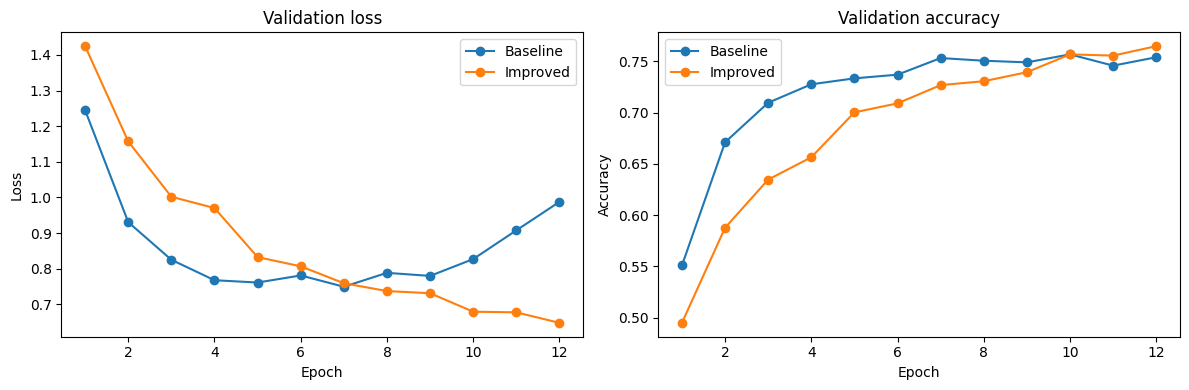

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(baseline_history["epoch"], baseline_history["val_loss"], marker="o", label="Baseline")
axes[0].plot(improved_history["epoch"], improved_history["val_loss"], marker="o", label="Improved")
axes[0].set_title("Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(baseline_history["epoch"], baseline_history["val_accuracy"], marker="o", label="Baseline")
axes[1].plot(improved_history["epoch"], improved_history["val_accuracy"], marker="o", label="Improved")
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Compare final validation metrics

In [10]:
comparison = pd.DataFrame([
    {
        "model": "Baseline",
        "best_validation_loss": min(baseline_history["val_loss"]),
        "best_validation_accuracy": max(baseline_history["val_accuracy"]),
        "epochs_run": len(baseline_history["epoch"])
    },
    {
        "model": "Improved (augmentation + dropout + weight decay + scheduler/early stopping)",
        "best_validation_loss": min(improved_history["val_loss"]),
        "best_validation_accuracy": max(improved_history["val_accuracy"]),
        "epochs_run": len(improved_history["epoch"])
    }
])
comparison

,model,best_validation_loss,best_validation_accuracy,epochs_run
0,Baseline,0.749240,0.7568,12
1,Improved (augmentation + dropout + weight deca...,0.647767,0.7648,12


Final test evaluation

The test set is used only now, after model training and validation comparison.

In [11]:
baseline_test_loss, baseline_test_acc = run_epoch(baseline_model, test_loader)
improved_test_loss, improved_test_acc = run_epoch(improved_model, test_loader)

test_comparison = pd.DataFrame([
    {"model": "Baseline", "test_loss": baseline_test_loss, "test_accuracy": baseline_test_acc},
    {"model": "Improved", "test_loss": improved_test_loss, "test_accuracy": improved_test_acc}
])
test_comparison

,model,test_loss,test_accuracy
0,Baseline,0.765949,0.7456
1,Improved,0.667276,0.7697


Save the results

In [12]:
comparison.to_csv("module2_validation_comparison.csv", index=False)
test_comparison.to_csv("module2_test_comparison.csv", index=False)
print("Saved module2_validation_comparison.csv and module2_test_comparison.csv")

Saved module2_validation_comparison.csv and module2_test_comparison.csv


My conclusion

After running the notebook, write a short conclusion in your own words:

- Which model had the better validation accuracy and validation loss?
- Did the improved model show a smaller gap between training and validation accuracy?
- Did the learning-rate scheduler reduce the learning rate?
- What would you try next if the validation results did not improve?

A more complicated model or more regularization does not always win. Use the actual results from your run to explain what happened.